# Ön İşleme – YOLO Formatına Dönüştürme

VisDrone2019-DET ve UAVDT-M etiketleri YOLO formatına (`sınıf cx cy w h`, 0–1 aralığında) çevrilmektedir.

- **VisDrone:** ignored regions (0) ve others (11) kutuları atılır; sınıflar 1–10 → 0–9.
- **UAVDT:** train dizilerinden 6'sı (yüksek irtifa dizisi hariç, tohum 42) dizi bazında doğrulama kümesine ayrılır; train ve val'de 10 karede bir örnekleme yapılır, test tam bırakılır; etiketsiz kareler atılır.
- **Ortak:** Görüntü sınırını aşan kutular kırpılır, kırpma sonrası alanı sıfır kalan kutular atılır.

In [2]:
import sys
from pathlib import Path

import pandas as pd

KOK = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(KOK))

from src.yolo_formatina_cevir import visdrone_cevir, uavdt_cevir

VERI = KOK / "data"
YOLO = VERI / "yolo"
print("Hedef klasör:", YOLO)

Hedef klasör: c:\Users\betul\Documents\uyz_uav_object_detection\data\yolo


In [3]:
visdrone_ozet = visdrone_cevir(VERI, YOLO / "visdrone")
pd.DataFrame(visdrone_ozet)

VisDrone test: 100%|██████████| 1610/1610 [00:16<00:00, 98.22it/s] 


,veri seti,bölüm,görüntü (önce),görüntü (sonra),kutu (önce),atılan: ignored/others,atılan: geçersiz kutu,atılan: etiketsiz kare,kutu (sonra)
0,VisDrone,train,6471,6471,353550,10345,1,0,343204
1,VisDrone,val,548,548,40169,1410,0,0,38759
2,VisDrone,test,1610,1610,77547,2445,0,0,75102


In [4]:
uavdt_ozet, val_diziler = uavdt_cevir(VERI / "UAVDT", YOLO / "uavdt")
print("Doğrulama (val) için ayrılan diziler:", val_diziler)
pd.DataFrame(uavdt_ozet)

UAVDT: 100%|██████████| 50/50 [03:10<00:00,  3.80s/it]

Doğrulama (val) için ayrılan diziler: ['M0202', 'M0604', 'M0605', 'M0902', 'M1003', 'M1201']


,veri seti,bölüm,görüntü (önce),görüntü (sonra),kutu (önce),atılan: ignored/others,atılan: geçersiz kutu,atılan: etiketsiz kare,kutu (sonra)
0,UAVDT,train,19059,1884,348386,0,0,31,34951
1,UAVDT,val,5084,511,74525,0,0,0,7492
2,UAVDT,test,16592,16580,375884,0,0,12,375884


In [5]:

from collections import Counter

from src.visdrone_okuma import SINIF_ADLARI as VISDRONE_SINIFLAR
from src.uavdt_okuma import SINIF_ADLARI as UAVDT_SINIFLAR


def sinif_sayilari(etiket_klasoru, sinif_adlari):
    """YOLO etiket dosyalarındaki kutuları sınıflara göre sayar."""
    sayac = Counter()
    for dosya in Path(etiket_klasoru).glob("*.txt"):
        for satir in dosya.read_text(encoding="utf-8").splitlines():
            sayac[int(satir.split()[0])] += 1
    return {ad: sayac.get(i, 0) for i, ad in enumerate(sinif_adlari)}


visdrone_adlar = [VISDRONE_SINIFLAR[i] for i in range(1, 11)]
uavdt_adlar = [UAVDT_SINIFLAR[i] for i in range(1, 4)]

visdrone_sinif = pd.DataFrame({b: sinif_sayilari(YOLO / "visdrone" / "labels" / b, visdrone_adlar)
                               for b in ["train", "val", "test"]})
uavdt_sinif = pd.DataFrame({b: sinif_sayilari(YOLO / "uavdt" / "labels" / b, uavdt_adlar)
                            for b in ["train", "val", "test"]})

print("VisDrone – YOLO etiketlerindeki sınıf sayıları:")
display(visdrone_sinif)
print("UAVDT – YOLO etiketlerindeki sınıf sayıları:")
display(uavdt_sinif)

VisDrone – YOLO etiketlerindeki sınıf sayıları:


,train,val,test
pedestrian,79337,8844,21006
people,27059,5125,6376
bicycle,10480,1287,1302
car,144866,14064,28074
van,24956,1975,5771
truck,12875,750,2659
tricycle,4812,1045,530
awning-tricycle,3246,532,599
bus,5926,251,2940
motor,29647,4886,5845


UAVDT – YOLO etiketlerindeki sınıf sayıları:


,train,val,test
car,32801,6796,361055
truck,1146,614,7595
bus,1004,82,7234


In [6]:
on_isleme = pd.DataFrame(visdrone_ozet + uavdt_ozet)
on_isleme.to_csv(KOK / "reports" / "on_isleme_ozeti.csv", index=False, encoding="utf-8-sig")
on_isleme

,veri seti,bölüm,görüntü (önce),görüntü (sonra),kutu (önce),atılan: ignored/others,atılan: geçersiz kutu,atılan: etiketsiz kare,kutu (sonra)
0,VisDrone,train,6471,6471,353550,10345,1,0,343204
1,VisDrone,val,548,548,40169,1410,0,0,38759
2,VisDrone,test,1610,1610,77547,2445,0,0,75102
3,UAVDT,train,19059,1884,348386,0,0,31,34951
4,UAVDT,val,5084,511,74525,0,0,0,7492
5,UAVDT,test,16592,16580,375884,0,0,12,375884


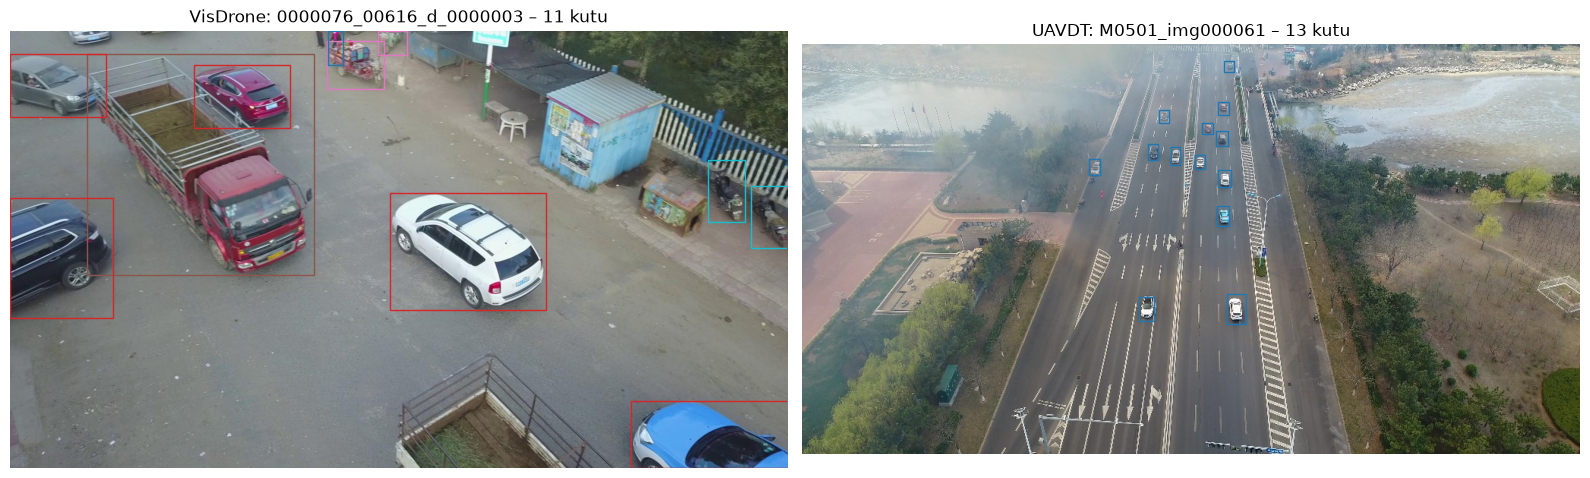

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


def yolo_ciz(ax, goruntu_yolu, etiket_yolu, sinif_adlari, baslik):
    """YOLO etiketini piksel koordinatına geri çevirip görüntü üzerine çizer."""
    img = Image.open(goruntu_yolu)
    gen, yuk = img.size
    ax.imshow(img)
    renkler = plt.cm.tab10
    satirlar = Path(etiket_yolu).read_text(encoding="utf-8").splitlines()
    for satir in satirlar:
        s, cx, cy, w, h = satir.split()
        s = int(s)
        cx, cy, w, h = float(cx) * gen, float(cy) * yuk, float(w) * gen, float(h) * yuk
        ax.add_patch(patches.Rectangle((cx - w / 2, cy - h / 2), w, h,
                                       fill=False, edgecolor=renkler(s), linewidth=1))
    ax.set_title(f"{baslik} – {len(satirlar)} kutu")
    ax.axis("off")


vis_ornek = sorted((YOLO / "visdrone" / "images" / "train").glob("*.jpg"))[100]
uav_ornek = sorted((YOLO / "uavdt" / "images" / "train").glob("*.jpg"))[500]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
yolo_ciz(axes[0], vis_ornek, YOLO / "visdrone" / "labels" / "train" / f"{vis_ornek.stem}.txt",
         visdrone_adlar, f"VisDrone: {vis_ornek.stem}")
yolo_ciz(axes[1], uav_ornek, YOLO / "uavdt" / "labels" / "train" / f"{uav_ornek.stem}.txt",
         uavdt_adlar, f"UAVDT: {uav_ornek.stem}")
plt.tight_layout()
plt.savefig(KOK / "reports" / "figures" / "on_isleme_yolo_kontrol.png", dpi=150)
plt.show()

## Ön İşleme Sonuçları

- **VisDrone:** Görüntü sayıları korundu (6.471 / 548 / 1.610). Ignored/others kutuları atıldı (10.345 / 1.410 / 2.445); 1 kutu kırpma sonrası geçersiz kaldı. Kalan kutular: 343.204 / 38.759 / 75.102.
- **UAVDT:** Doğrulama dizileri M0202, M0604, M0605, M0902, M1003, M1201. Train 19.059 → 1.884 kare (34.951 kutu), val 5.084 → 511 kare (7.492 kutu), test 16.592 → 16.580 kare (375.884 kutu). Örnekleme sonrası atılan etiketsiz kare: train 31, test 12.
- **Sınıf dengesi (UAVDT, örnekleme sonrası):** train'de car 32.801, truck 1.146, bus 1.004; val'de bus yalnızca 82 kutu → bus için doğrulama sonuçları oynak olabilir.
- **Kontrol:** YOLO etiketleri piksele geri çevrilerek çizildi; kutular nesnelerle örtüşüyor.
- **Kısıt:** VisDrone ignored bölgeleri ve UAVDT `_gt_ignore` bölgeleri görüntüde maskelenmedi.